# Exercise 25 – A double well: Monte Carlo vs molecular dynamics

**Week 5 · Molecular dynamics**

$$V(x) = \tfrac12 x^2 + A\,e^{-(x-x_1)^2/\lambda^2}, \qquad A = -1,\ x_1 = 1.5,\ \lambda = 0.25$$

has a narrow well at $x \approx 1.5$ next to the broad harmonic well. MD
moves continuously, so to go from one well to the other it has to cross the
barrier; Monte Carlo with uniform proposals can jump.

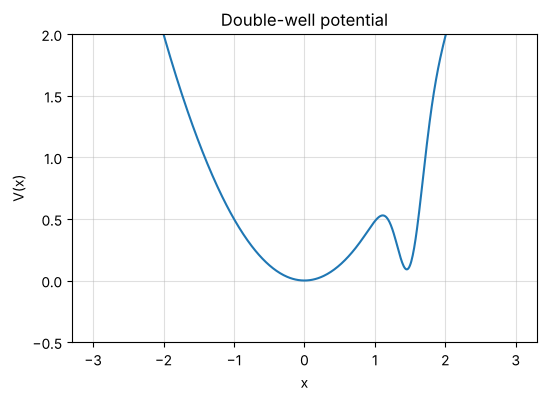

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.md import thermostatted_md
from comphy.montecarlo import boltzmann_pdf, metropolis

rng = np.random.default_rng(0)
A, x1, lam = -1.0, 1.5, 0.25


def V(x):
    x = np.asarray(x, dtype=float)
    return 0.5 * x**2 + A * np.exp(-((x - x1) ** 2) / lam**2)


def force(x):
    return -x + 2 * A * (x - x1) / lam**2 * np.exp(-((x - x1) ** 2) / lam**2)


grid = np.linspace(-3, 3, 600)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(grid, V(grid))
ax.set(xlabel="x", ylabel="V(x)", title="Double-well potential", ylim=(-0.5, 2))
ax.grid(True, alpha=0.4)
plt.show()

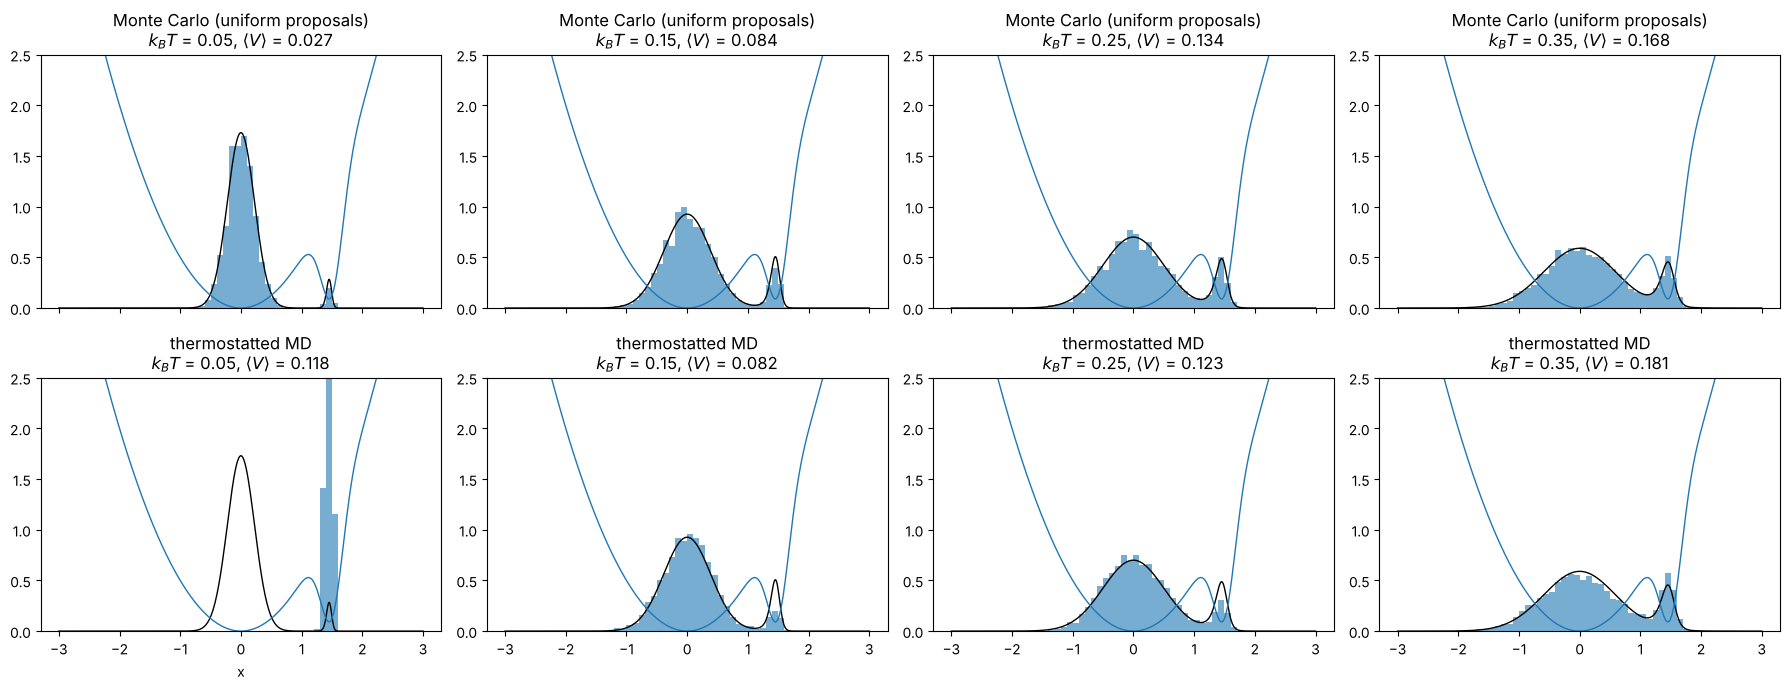

In [2]:
kTs = [0.05, 0.15, 0.25, 0.35]
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=True)
for col, kT in enumerate(kTs):
    pdf = boltzmann_pdf(V, kT, (-3, 3))
    mc_x, acc = metropolis(V, kT, x0=1.5, n_steps=20_000, lims=(-3, 3), rng=rng)
    md_x, _ = thermostatted_md(1.5, force, kT, n_segments=5_000, steps_per_segment=50,
                               dt=0.01, rng=rng)
    for ax, sample, name in [(axes[0, col], mc_x, "Monte Carlo (uniform proposals)"),
                             (axes[1, col], md_x, "thermostatted MD")]:
        ax.hist(sample, bins=60, range=(-3, 3), density=True, alpha=0.6)
        ax.plot(grid, pdf(grid), color="black", lw=1)
        ax.plot(grid, V(grid), color="C0", lw=1)
        ax.set(ylim=(0, 2.5), title=f"{name}\n$k_BT$ = {kT}, ⟨V⟩ = {V(sample).mean():.3f}"
               .replace("⟨V⟩", r"$\langle V\rangle$"))
axes[1, 0].set_xlabel("x")
fig.tight_layout()
plt.show()

Monte Carlo with uniform proposals reproduces the Boltzmann distribution
(black) at every temperature. The MD walker starts in the narrow well: at
$k_BT = 0.05$ it never gets over the barrier and the sampled distribution is
completely wrong. From $k_BT = 0.15$ on, barrier crossings happen often enough
and MD agrees with the exact result. Continuous dynamics can get trapped where
Monte Carlo jumps freely.